# 3. Análise Exploratória dos Dados (EDA) — NPS Preditivo

**Objetivo:** entender, com foco em negócio, o que separa clientes satisfeitos de insatisfeitos.

Perguntas que este notebook responde:

- **3.1** Quais fatores parecem mais críticos para a satisfação?
- **3.2** O que mais gera detratores?
- **3.3** Existe algum "ponto de ruptura" na experiência do cliente?
- **3.4** Que tipo de cliente tende a ter NPS mais alto ou mais baixo?

O resumo em linguagem de negócio está em `reports/03_eda.md`.

## Preparação: carga e qualidade dos dados

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Caminhos relativos à raiz do repositório (o notebook roda de dentro de notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "desafio_nps_fase_1.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Padrão visual: uma cor para magnitude, cores de status para as faixas de NPS
COLOR_MAIN = "#2a78d6"
COLOR_MUTED = "#b8b7b0"
COLOR_DETRACTOR = "#d03b3b"
COLOR_NEUTRAL = "#b8b7b0"
COLOR_PROMOTER = "#0ca30c"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b8b7b0", "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e8e7e2", "grid.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

df = pd.read_csv(DATA_PATH)
print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")
df.head()

Linhas: 2500 | Colunas: 19


,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


In [2]:
# Checagem de qualidade: nulos, duplicados e unicidade das chaves
quality = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isnull().sum(),
    "valores_unicos": df.nunique(),
})
print("Linhas duplicadas:", df.duplicated().sum())
print("Cada linha é um cliente/pedido único:",
      df["customer_id"].is_unique and df["order_id"].is_unique)
quality

Linhas duplicadas: 0
Cada linha é um cliente/pedido único: True


,tipo,nulos,valores_unicos
customer_id,int64,0,2500
customer_age,int64,0,52
customer_region,str,0,5
customer_tenure_months,int64,0,119
order_id,int64,0,2500
order_value,float64,0,2457
items_quantity,int64,0,6
discount_value,float64,0,2050
payment_installments,int64,0,11
delivery_time_days,int64,0,13


**Leitura:** base limpa — 2.500 pedidos, um por cliente, sem nulos nem duplicados. Não foi
necessário tratamento de valores ausentes. A única preparação é criar a faixa de NPS abaixo.

## Visão geral da satisfação (target)

Classificação padrão de mercado do NPS: **detrator** (nota 0 a 6), **neutro** (7 a 8) e
**promotor** (9 a 10). Como a nota da base tem casas decimais, usamos os cortes `< 7` e `>= 9`.

NPS = % de promotores − % de detratores.

In [3]:
def classify_nps(score: float) -> str:
    """Converte a nota de NPS (0-10) na faixa padrão de mercado."""
    if score >= 9:
        return "Promotor"
    if score >= 7:
        return "Neutro"
    return "Detrator"


df["nps_category"] = df["nps_score"].apply(classify_nps)
df["is_detractor"] = df["nps_category"].eq("Detrator")
df["is_promoter"] = df["nps_category"].eq("Promotor")

category_share = (df["nps_category"].value_counts(normalize=True)
                  .reindex(["Detrator", "Neutro", "Promotor"]) * 100)
nps_overall = category_share["Promotor"] - category_share["Detrator"]

print(category_share.round(1).to_string())
print(f"\nNPS geral da base: {nps_overall:.0f}")
print(f"Nota média: {df['nps_score'].mean():.1f} | Mediana: {df['nps_score'].median():.1f}")

nps_category
Detrator    84.4
Neutro      11.2
Promotor     4.4

NPS geral da base: -80
Nota média: 4.4 | Mediana: 4.4


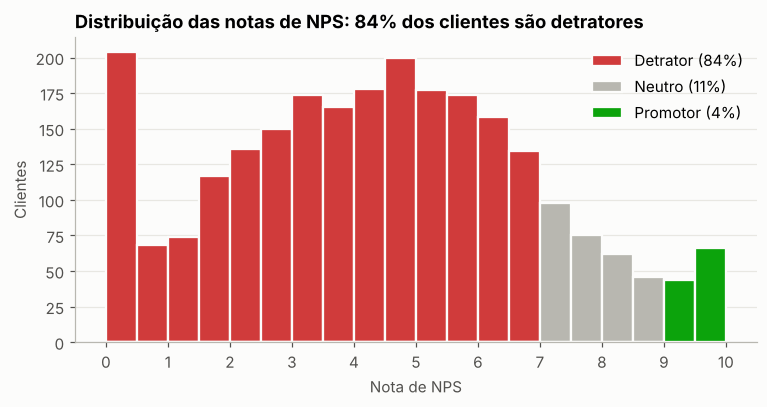

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.arange(0, 10.5, 0.5)
for label, color in [("Detrator", COLOR_DETRACTOR), ("Neutro", COLOR_NEUTRAL),
                     ("Promotor", COLOR_PROMOTER)]:
    subset = df.loc[df["nps_category"] == label, "nps_score"]
    ax.hist(subset, bins=bins, color=color, edgecolor="#fcfcfb", linewidth=1.5,
            label=f"{label} ({category_share[label]:.0f}%)")
ax.set_title("Distribuição das notas de NPS: 84% dos clientes são detratores")
ax.set_xlabel("Nota de NPS")
ax.set_ylabel("Clientes")
ax.set_xticks(range(0, 11))
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
fig.savefig(FIG_DIR / "01_distribuicao_nps.png")
plt.show()

**Leitura:** o problema é generalizado, não de nicho. **84% dos clientes são detratores** e só
4% são promotores, resultando em um NPS de **−80**. A nota média é 4,4.

## 3.1 Quais fatores parecem mais críticos para a satisfação?

Primeiro olhamos a força da relação de cada variável com a nota (correlação). Quanto mais longe
de zero, mais a variável "anda junto" com o NPS; negativa significa que, quando ela sobe, o NPS cai.

Duas variáveis ficam **fora** dessa comparação de fatores operacionais, e o motivo é importante:

- `repeat_purchase_30d` acontece **depois** da compra — é consequência da satisfação, não causa.
- `csat_internal_score` é outra medida de satisfação, não um fator da operação.

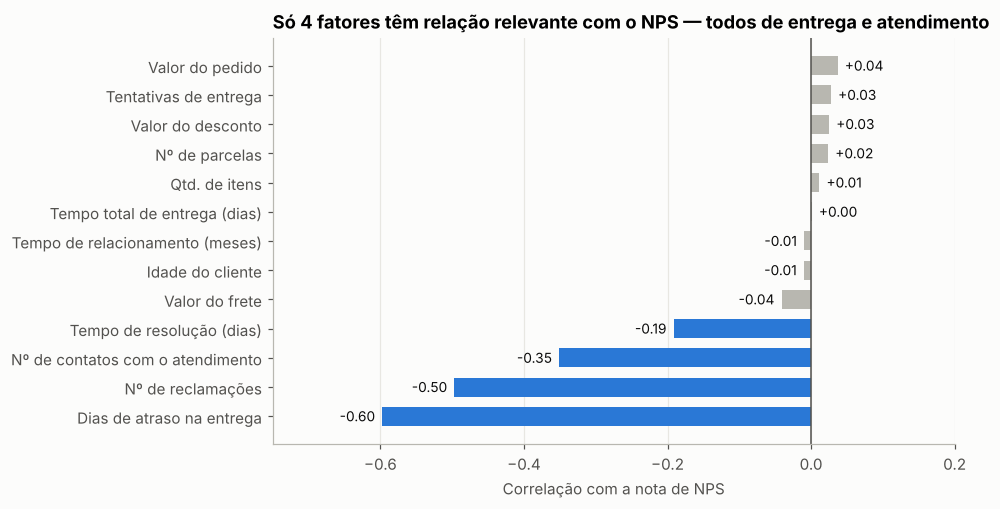

In [5]:
OPERATIONAL_FEATURES = {
    "delivery_delay_days": "Dias de atraso na entrega",
    "complaints_count": "Nº de reclamações",
    "customer_service_contacts": "Nº de contatos com o atendimento",
    "resolution_time_days": "Tempo de resolução (dias)",
    "freight_value": "Valor do frete",
    "order_value": "Valor do pedido",
    "delivery_attempts": "Tentativas de entrega",
    "discount_value": "Valor do desconto",
    "payment_installments": "Nº de parcelas",
    "items_quantity": "Qtd. de itens",
    "customer_age": "Idade do cliente",
    "customer_tenure_months": "Tempo de relacionamento (meses)",
    "delivery_time_days": "Tempo total de entrega (dias)",
}

correlations = (df[list(OPERATIONAL_FEATURES)].corrwith(df["nps_score"])
                .rename(index=OPERATIONAL_FEATURES).sort_values())

fig, ax = plt.subplots(figsize=(8, 4.8))
bar_colors = [COLOR_MAIN if abs(v) >= 0.15 else COLOR_MUTED for v in correlations]
ax.barh(correlations.index, correlations.values, color=bar_colors, height=0.65)
for y, value in enumerate(correlations.values):
    ax.text(value - 0.01 if value < 0 else value + 0.01, y, f"{value:+.2f}",
            va="center", ha="right" if value < 0 else "left", fontsize=9, color="#0b0b0b")
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_xlim(-0.75, 0.2)
ax.set_title("Só 4 fatores têm relação relevante com o NPS — todos de entrega e atendimento")
ax.set_xlabel("Correlação com a nota de NPS")
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "02_correlacao_fatores.png")
plt.show()

**Leitura:** dos 13 fatores, só **quatro** importam, e todos são de **entrega e atendimento**:
atraso na entrega (−0,60), reclamações (−0,50), contatos com o atendimento (−0,35) e tempo de
resolução (−0,19). Valor do pedido, frete, desconto, parcelas, idade, região e tempo de casa
praticamente não mexem na nota.

Um detalhe que muda a conversa com a logística: o **tempo total de entrega não tem relação
nenhuma** com o NPS (0,00). O cliente não se incomoda com prazo longo; ele se incomoda com
**prazo descumprido**.

## 3.2 O que mais gera detratores?

Para cada fator crítico, olhamos a nota média e a porcentagem de detratores em cada nível.

In [6]:
def summarize_by(column: str) -> pd.DataFrame:
    """Nota média, % de detratores e % de promotores para cada valor de uma coluna."""
    return (df.groupby(column)
              .agg(clientes=("nps_score", "size"),
                   nota_media=("nps_score", "mean"),
                   pct_detratores=("is_detractor", "mean"),
                   pct_promotores=("is_promoter", "mean"))
              .assign(pct_detratores=lambda t: t["pct_detratores"] * 100,
                      pct_promotores=lambda t: t["pct_promotores"] * 100)
              .round(1))


def plot_detractor_rate(summary: pd.DataFrame, title: str, xlabel: str, filename: str,
                        min_clients: int = 30) -> None:
    """Barras com % de detratores por nível; ignora níveis com poucos clientes."""
    data = summary[summary["clientes"] >= min_clients]
    fig, ax = plt.subplots(figsize=(8, 3.6))
    bars = ax.bar(data.index.astype(str), data["pct_detratores"], color=COLOR_DETRACTOR,
                  width=0.7)
    for bar, (_, row) in zip(bars, data.iterrows()):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
                f"{row['pct_detratores']:.0f}%", ha="center", fontsize=9, color="#0b0b0b")
        ax.text(bar.get_x() + bar.get_width() / 2, 3, f"nota\n{row['nota_media']:.1f}",
                ha="center", fontsize=8, color="white")
    ax.set_ylim(0, 112)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("% de detratores")
    ax.grid(axis="x", visible=False)
    fig.savefig(FIG_DIR / filename)
    plt.show()


delay_summary = summarize_by("delivery_delay_days")
delay_summary

,clientes,nota_media,pct_detratores,pct_promotores
delivery_delay_days,,,,
0,277,6.9,51.6,18.1
1,615,5.5,74.0,7.2
2,646,4.6,87.9,2.0
3,525,3.4,96.8,0.6
4,270,2.4,99.3,0.0
5,116,1.5,100.0,0.0
6,34,1.1,100.0,0.0
7,14,0.3,100.0,0.0
8,3,0.0,100.0,0.0


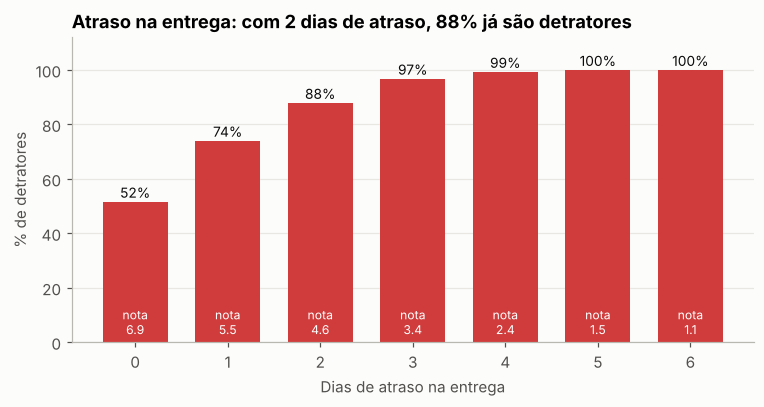

Pedidos entregues no prazo: 11%
Pedidos com 2 ou mais dias de atraso: 64%


In [7]:
plot_detractor_rate(delay_summary,
                    "Atraso na entrega: com 2 dias de atraso, 88% já são detratores",
                    "Dias de atraso na entrega", "03_detratores_por_atraso.png")
on_time_share = df["delivery_delay_days"].eq(0).mean() * 100
late_2plus_share = df["delivery_delay_days"].ge(2).mean() * 100
print(f"Pedidos entregues no prazo: {on_time_share:.0f}%")
print(f"Pedidos com 2 ou mais dias de atraso: {late_2plus_share:.0f}%")

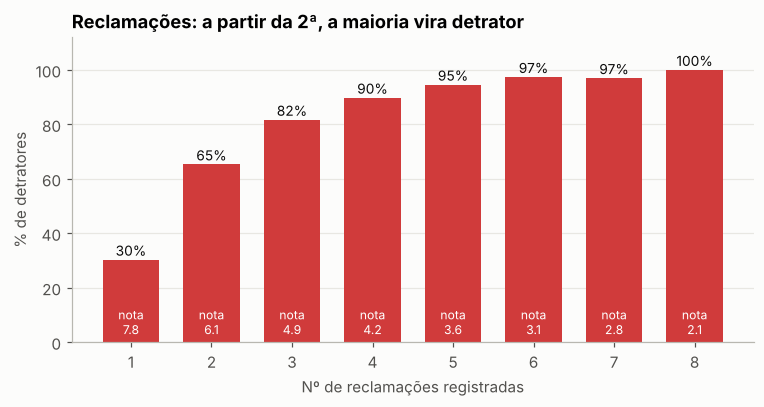

,clientes,nota_media,pct_detratores,pct_promotores
complaints_count,,,,
0,23,8.5,17.4,39.1
1,122,7.8,30.3,21.3
2,277,6.1,65.3,11.2
3,507,4.9,81.7,4.5
4,600,4.2,89.8,2.8
5,444,3.6,94.6,0.7
6,266,3.1,97.4,0.0
7,169,2.8,97.0,0.0
8,63,2.1,100.0,0.0


In [8]:
complaints_summary = summarize_by("complaints_count")
plot_detractor_rate(complaints_summary,
                    "Reclamações: a partir da 2ª, a maioria vira detrator",
                    "Nº de reclamações registradas", "04_detratores_por_reclamacoes.png")
complaints_summary

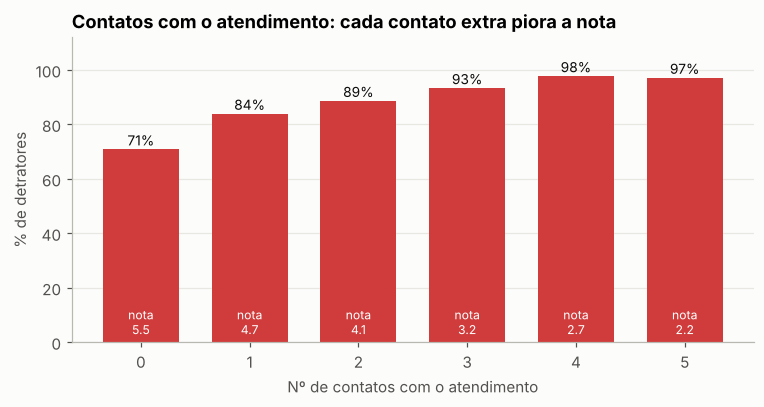

,clientes,nota_media,pct_detratores,pct_promotores
customer_service_contacts,,,,
0,554,5.5,70.8,10.3
1,816,4.7,83.9,4.4
2,640,4.1,88.6,2.2
3,314,3.2,93.3,0.6
4,132,2.7,97.7,0.8
5,34,2.2,97.1,0.0
6,7,0.7,100.0,0.0
7,3,1.2,100.0,0.0


In [9]:
contacts_summary = summarize_by("customer_service_contacts")
plot_detractor_rate(contacts_summary,
                    "Contatos com o atendimento: cada contato extra piora a nota",
                    "Nº de contatos com o atendimento", "05_detratores_por_contatos.png")
contacts_summary

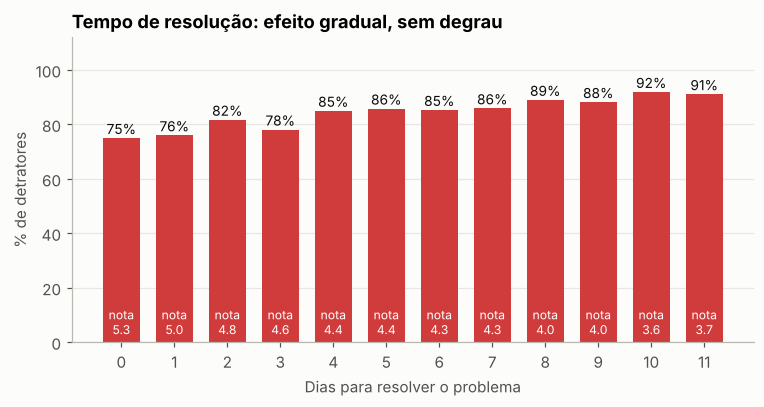

In [10]:
resolution_summary = summarize_by("resolution_time_days")
plot_detractor_rate(resolution_summary,
                    "Tempo de resolução: efeito gradual, sem degrau",
                    "Dias para resolver o problema", "06_detratores_por_resolucao.png")

**Leitura:**

- **Atraso na entrega é o maior gerador de detratores.** No prazo, 52% são detratores; com 1 dia
  de atraso, 74%; com 2 dias, 88%; com 3 ou mais, praticamente todos (97% a 100%). E só **11%
  dos pedidos chegam no prazo**; 64% chegam com 2 dias ou mais de atraso.
- **Reclamações vêm em segundo.** Com 0 ou 1 reclamação a nota média fica perto de 8; na 2ª cai
  para 6,1 e 65% já são detratores. 94% dos clientes têm 2 ou mais reclamações.
- **Contatos com o atendimento** pioram a nota a cada contato adicional (de 5,5 sem contato para
  2,7 com quatro).
- **Tempo de resolução** pesa menos e de forma gradual: de 75% de detratores quando resolve no
  dia para 91% quando leva 10 dias ou mais.

## 3.3 Existe algum "ponto de ruptura" na experiência do cliente?

Um ponto de ruptura é o nível a partir do qual a satisfação despenca e fica quase impossível de
recuperar. Olhamos a chance de o cliente **não** ser detrator em cada combinação de atraso e
reclamações.

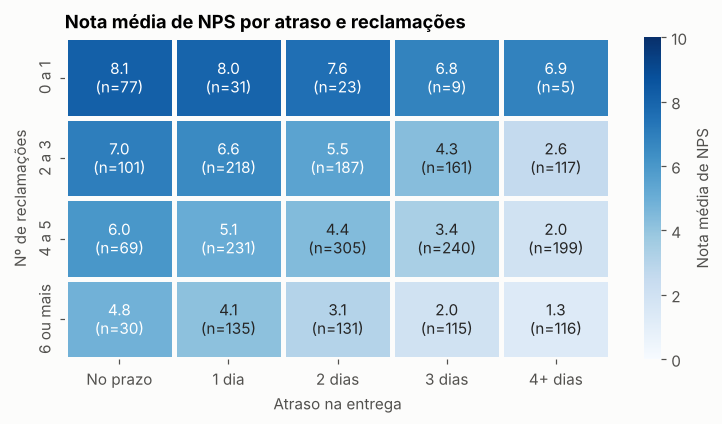

In [11]:
heat = df.assign(
    atraso=df["delivery_delay_days"].clip(upper=4).map(
        {0: "No prazo", 1: "1 dia", 2: "2 dias", 3: "3 dias", 4: "4+ dias"}),
    reclamacoes=pd.cut(df["complaints_count"], [-1, 1, 3, 5, 20],
                       labels=["0 a 1", "2 a 3", "4 a 5", "6 ou mais"]),
)
delay_order = ["No prazo", "1 dia", "2 dias", "3 dias", "4+ dias"]
mean_score = heat.pivot_table(index="reclamacoes", columns="atraso", values="nps_score",
                              aggfunc="mean", observed=True)[delay_order]
client_count = heat.pivot_table(index="reclamacoes", columns="atraso", values="nps_score",
                                aggfunc="size", observed=True)[delay_order]

annotations = mean_score.round(1).astype(str) + "\n(n=" + client_count.astype(str) + ")"
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.heatmap(mean_score, annot=annotations, fmt="", cmap="Blues", vmin=0, vmax=10,
            linewidths=2, linecolor="#fcfcfb", cbar_kws={"label": "Nota média de NPS"}, ax=ax)
ax.set_title("Nota média de NPS por atraso e reclamações")
ax.set_xlabel("Atraso na entrega")
ax.set_ylabel("Nº de reclamações")
ax.grid(False)
fig.savefig(FIG_DIR / "07_ruptura_atraso_x_reclamacoes.png")
plt.show()

In [12]:
# Quantos promotores existem depois de cada limite?
for label, mask in [
    ("Atraso de 2 dias ou mais", df["delivery_delay_days"] >= 2),
    ("Atraso de 3 dias ou mais", df["delivery_delay_days"] >= 3),
    ("4 reclamações ou mais", df["complaints_count"] >= 4),
    ("No prazo E até 1 reclamação", (df["delivery_delay_days"] == 0)
                                    & (df["complaints_count"] <= 1)),
]:
    group = df[mask]
    print(f"{label:<30} clientes: {len(group):>5} | detratores: "
          f"{group['is_detractor'].mean() * 100:>3.0f}% | promotores: "
          f"{group['is_promoter'].mean() * 100:>3.0f}%")

Atraso de 2 dias ou mais       clientes:  1608 | detratores:  94% | promotores:   1%
Atraso de 3 dias ou mais       clientes:   962 | detratores:  98% | promotores:   0%
4 reclamações ou mais          clientes:  1571 | detratores:  94% | promotores:   1%
No prazo E até 1 reclamação    clientes:    77 | detratores:  25% | promotores:  34%


**Leitura:** existem dois pontos de ruptura claros.

1. **Segundo dia de atraso.** Até 1 dia de atraso ainda existe chance de recuperar o cliente. A
   partir de 2 dias, 94% são detratores e só 1% é promotor. A partir de 3 dias, o cliente está
   perdido (98% de detratores).
2. **Segunda reclamação.** Clientes com 0 ou 1 reclamação seguem com nota média perto de 8 mesmo
   com 1 ou 2 dias de atraso. Da 2ª reclamação em diante a nota cai e o atraso passa a pesar
   muito mais.

Os dois problemas **se somam**: o pior cenário (4+ dias de atraso e 6+ reclamações) tem nota
média 1,3; o melhor (no prazo e até 1 reclamação) tem 8,1.

## 3.4 Que tipo de cliente tende a ter NPS mais alto ou mais baixo?

Comparamos a nota média por perfil do cliente e do pedido.

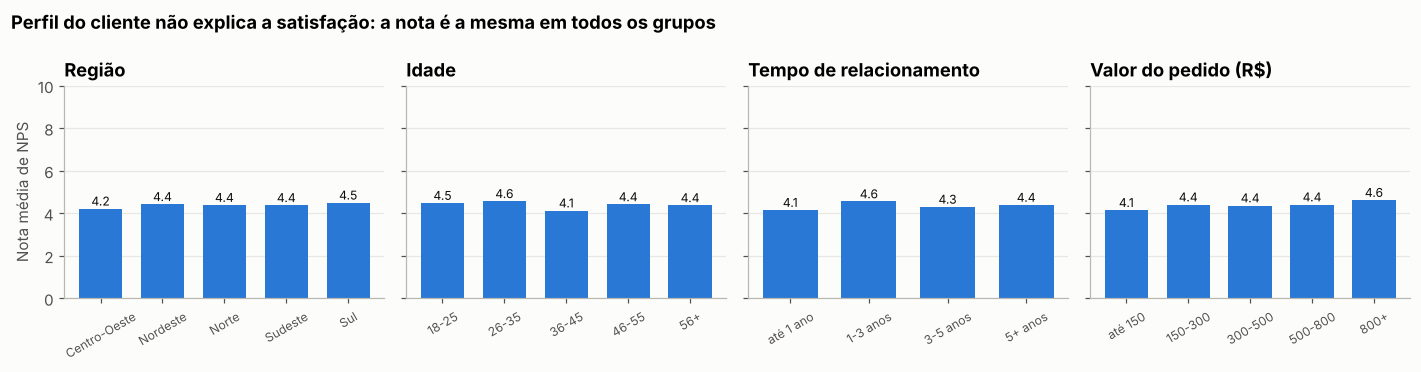

In [13]:
profile = df.assign(
    faixa_idade=pd.cut(df["customer_age"], [17, 25, 35, 45, 55, 70],
                       labels=["18-25", "26-35", "36-45", "46-55", "56+"]),
    faixa_tempo_casa=pd.cut(df["customer_tenure_months"], [0, 12, 36, 60, 120],
                            labels=["até 1 ano", "1-3 anos", "3-5 anos", "5+ anos"]),
    faixa_valor=pd.cut(df["order_value"], [0, 150, 300, 500, 800, 2000],
                       labels=["até 150", "150-300", "300-500", "500-800", "800+"]),
)
panels = [("customer_region", "Região"), ("faixa_idade", "Idade"),
          ("faixa_tempo_casa", "Tempo de relacionamento"), ("faixa_valor", "Valor do pedido (R$)")]

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True)
for ax, (column, title) in zip(axes, panels):
    means = profile.groupby(column, observed=True)["nps_score"].mean()
    ax.bar(means.index.astype(str), means.values, color=COLOR_MAIN, width=0.7)
    for x, value in enumerate(means.values):
        ax.text(x, value + 0.15, f"{value:.1f}", ha="center", fontsize=8, color="#0b0b0b")
    ax.set_title(title)
    ax.set_ylim(0, 10)
    ax.tick_params(axis="x", labelrotation=30, labelsize=8)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Nota média de NPS")
fig.suptitle("Perfil do cliente não explica a satisfação: a nota é a mesma em todos os grupos",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "08_nps_por_perfil.png")
plt.show()

In [14]:
# Em vez de perfil demográfico, o que diferencia é a experiência vivida no pedido
experience_groups = {
    "Experiência boa (no prazo, até 1 reclamação)":
        (df["delivery_delay_days"] == 0) & (df["complaints_count"] <= 1),
    "Experiência ruim (3+ dias de atraso ou 6+ reclamações)":
        (df["delivery_delay_days"] >= 3) | (df["complaints_count"] >= 6),
}
for label, mask in experience_groups.items():
    group = df[mask]
    print(f"{label}\n  clientes: {len(group)} ({len(group) / len(df) * 100:.0f}% da base) | "
          f"nota média: {group['nps_score'].mean():.1f} | "
          f"detratores: {group['is_detractor'].mean() * 100:.0f}%\n")

Experiência boa (no prazo, até 1 reclamação)
  clientes: 77 (3% da base) | nota média: 8.1 | detratores: 25%

Experiência ruim (3+ dias de atraso ou 6+ reclamações)
  clientes: 1258 (50% da base) | nota média: 3.0 | detratores: 97%



**Leitura:** não existe um "tipo de cliente" insatisfeito. Região, idade, tempo de relacionamento
e valor do pedido têm todos a mesma nota média (entre 4,1 e 4,6). O que separa NPS alto de baixo
é **a experiência que o cliente teve naquele pedido**:

- **NPS alto:** recebeu no prazo e quase não precisou reclamar (nota média 8,1). São só 3% da base.
- **NPS baixo:** teve 3+ dias de atraso ou 6+ reclamações (nota média 3,0). São 50% da base.

## Cuidado: variáveis que não podem ser usadas para prever

Duas colunas têm relação forte com o NPS, mas não servem como "causa" nem como entrada de um
modelo preditivo.

In [15]:
repeat_summary = summarize_by("repeat_purchase_30d")
print("NPS por recompra em 30 dias (0 = não, 1 = sim):")
print(repeat_summary.to_string())
print(f"\nMenor nota entre quem recomprou: "
      f"{df.loc[df['repeat_purchase_30d'] == 1, 'nps_score'].min()}")
print(f"Correlação CSAT interno x NPS: {df['csat_internal_score'].corr(df['nps_score']):.2f}")
print(f"Taxa de recompra em 30 dias: {df['repeat_purchase_30d'].mean() * 100:.1f}%")

NPS por recompra em 30 dias (0 = não, 1 = sim):
                     clientes  nota_media  pct_detratores  pct_promotores
repeat_purchase_30d                                                      
0                        2282         3.9            92.4             0.0
1                         218         9.0             0.0            50.5

Menor nota entre quem recomprou: 8.0
Correlação CSAT interno x NPS: 0.56
Taxa de recompra em 30 dias: 8.7%


**Leitura:**

- **Recompra em 30 dias** é consequência da satisfação: todos os clientes que recompraram deram
  nota 8 ou mais, e nenhum detrator recomprou. Isso confirma o impacto do NPS na receita (só 9%
  da base recompra), mas a informação só existe depois da pesquisa — usá-la para prever seria
  vazamento de dados.
- **CSAT interno** é outra medida da mesma satisfação. Só pode entrar num modelo se estiver
  disponível antes da pesquisa de NPS, o que precisa ser confirmado com a área responsável.

## Conclusões da EDA

| Pergunta | Resposta curta |
|---|---|
| 3.1 Fatores mais críticos | Atraso na entrega, reclamações, contatos com o atendimento e tempo de resolução. Perfil do cliente e do pedido não importam. |
| 3.2 O que mais gera detratores | Atraso na entrega: 88% de detratores com 2 dias de atraso; só 11% dos pedidos chegam no prazo. |
| 3.3 Ponto de ruptura | 2º dia de atraso e 2ª reclamação. Depois disso quase não há promotores. |
| 3.4 Tipo de cliente | Não é perfil demográfico; é a experiência do pedido. No prazo e sem reclamar: nota 8,1. |

**Limitações:** a base é uma fotografia de 2.500 pedidos sem data; as relações são correlações e
não provam causa; o motivo das reclamações e dos contatos não está registrado.